### Linear spatial interpolation of an EEG channel
This notebook reconstructs the F3 EEG signal from four neighboring channels (Fp1, F7, C3, and Fz) using two-dimensional linear spatial interpolation based on electrode coordinates. The reconstructed signal is compared with the recorded F3 signal using correlation, RMSE, mutual information, spectral coherence, and Jensen–Shannon measures.
Run this notebook from the project directory containing coordinates.csv and the Processed_data folder created by the preprocessing notebook. The original F3 signal is needed only to evaluate the reconstruction.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.interpolate import LinearNDInterpolator
from scipy.signal import coherence, welch
from scipy.spatial.distance import jensenshannon
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mutual_info_score

In [2]:
# Use paths relative to the project directory.
processed_dir = Path("Processed_data")
coordinates_path = Path("coordinates.csv")
# Reconstruct F3 for subjects sub-037 through sub-065.
subjects = range(37, 66)
target_channel = "F3"
neighbors = ["Fp1", "F7", "C3", "Fz"]

# Parameters for mutual information and spectral metrics.
n_bins = 64
nperseg = 1024

In [3]:
def normalize_label(label):
    """Standardize channel names for coordinate lookup."""
    return str(label).strip().upper()


def load_coordinates(path):
    """Load electrode XYZ coordinates from a CSV file."""
    coords_df = pd.read_csv(path, sep=None, engine="python")

    required_cols = ["EEG Label", "X", "Y", "Z"]
    missing_cols = [col for col in required_cols if col not in coords_df.columns]

    if missing_cols:
        raise ValueError(f"Missing columns in coordinate file: {missing_cols}")

    coords = {}
    for _, row in coords_df.iterrows():
        label = normalize_label(row["EEG Label"])
        coords[label] = np.array([
            float(row["X"]),
            float(row["Y"]),
            float(row["Z"]),
        ])

    return coords

In [4]:
coords = load_coordinates(coordinates_path)

# Preserve the fixed Fz coordinate from the original analysis.
# This replaces the Fz value in the CSV if one is present.
coords["FZ"] = np.array([0.673028145, 0.0, 0.5])

In [5]:
def linear_spatial_interpolation(data, ch_names, coords, target_channel, available_neighbors):
    """Reconstruct a channel using linear interpolation of neighboring EEG signals in 2D."""
    target_label = normalize_label(target_channel)
    neighbor_labels = [normalize_label(ch) for ch in available_neighbors]

    # Both the target and neighboring electrodes need known coordinates.
    required_labels = [target_label] + neighbor_labels
    missing_coords = [label for label in required_labels if label not in coords]
    if missing_coords:
        raise ValueError(f"Missing coordinates for channels: {missing_coords}")

    # The recorded target channel is needed for evaluation of the reconstruction.
    missing_channels = [ch for ch in available_neighbors if ch not in ch_names]
    if target_channel not in ch_names:
        missing_channels.append(target_channel)
    if missing_channels:
        raise ValueError(f"Missing EEG channels: {missing_channels}")

    # Use X and Y coordinates for 2D interpolation; Z is not used.
    neighbor_xy = np.array([coords[label][:2] for label in neighbor_labels])
    target_xy = coords[target_label][:2]

    # The array has one row per neighboring channel and one column per time sample.
    neighbor_indices = [ch_names.index(ch) for ch in available_neighbors]
    neighbor_values = data[neighbor_indices]

    # SciPy interpolates the signal value at every time sample in one operation.
    interpolator = LinearNDInterpolator(neighbor_xy, neighbor_values)
    interpolated = np.asarray(interpolator(target_xy)).squeeze()

    # Interpolation is undefined outside the convex hull of the neighboring electrodes.
    if np.any(np.isnan(interpolated)):
        raise ValueError(
            f"{target_channel} lies outside the area formed by the neighboring "
            "electrodes; linear interpolation is not available."
        )

    return interpolated

In [6]:
def calculate_metrics(x, y, fs):
    """Compare recorded and reconstructed EEG signals in time and frequency domains."""
    # Pearson correlation and its p-value measure linear association.
    corr, p_value = pearsonr(x, y)
    rmse = np.sqrt(mean_squared_error(x, y))

    # Estimate mutual information after binning each signal into 64 intervals.
    x_binned = np.digitize(x, np.histogram_bin_edges(x, bins=n_bins))
    y_binned = np.digitize(y, np.histogram_bin_edges(y, bins=n_bins))
    mi = mutual_info_score(x_binned, y_binned)

    # Average the magnitude-squared coherence over the 1–45 Hz band.
    f_coh, coh = coherence(x, y, fs=fs, nperseg=nperseg)
    coh_mask = (f_coh >= 1) & (f_coh <= 45)
    mean_coherence_1_45 = np.mean(coh[coh_mask])

    # Compare normalized power spectral densities over the same band.
    f_psd, psd_x = welch(x, fs=fs, nperseg=nperseg)
    _, psd_y = welch(y, fs=fs, nperseg=nperseg)
    psd_mask = (f_psd >= 1) & (f_psd <= 45)

    psd_x_band = psd_x[psd_mask]
    psd_y_band = psd_y[psd_mask]

    # A zero-power spectrum cannot be normalized to a probability distribution.
    if psd_x_band.sum() == 0 or psd_y_band.sum() == 0:
        js_distance = np.nan
        js_divergence = np.nan
    else:
        psd_x_norm = psd_x_band / psd_x_band.sum()
        psd_y_norm = psd_y_band / psd_y_band.sum()

        js_distance = jensenshannon(psd_x_norm, psd_y_norm)
        js_divergence = js_distance ** 2

    # Keep the original column names for compatibility with the comparison notebook.
    return {
        "Pearsono koreliacija": corr,
        "p reikšmė": p_value,
        "RMSE": rmse,
        "Abipusė informacija": mi,
        "Vidutinė spektrinė koherencija": mean_coherence_1_45,
        "Jensen-Shannon atstumas": js_distance,
        "Jensen-Shannon divergencija": js_divergence,
    }

In [7]:
results = []

for sub in subjects:
    subject_code = f"sub-{sub:03d}"
    fif_path = processed_dir / f"{subject_code}_task-eyesclosed_eeg_cleaned_raw.fif"

    print(f"Processing {subject_code}")

    if not fif_path.exists():
        print(f"File not found: {fif_path}")
        results.append({"subjektas": subject_code, "statusas": "missing_file"})
        continue

    try:
        raw = mne.io.read_raw_fif(fif_path, preload=True, verbose=False)
        data = raw.get_data()
        ch_names = raw.ch_names
        fs = raw.info["sfreq"]

        if target_channel not in ch_names:
            print(f"Channel not found: {target_channel}")
            results.append({"subjektas": subject_code, "statusas": "missing_F3"})
            continue

        available_neighbors = [ch for ch in neighbors if ch in ch_names]
        if len(available_neighbors) < 3:
            print("At least three neighboring channels are required for 2D interpolation.")
            results.append({
                "subjektas": subject_code,
                "statusas": "not_enough_neighbors",
                "Kaimyniniai kanalai": ",".join(available_neighbors),
                "Kaimynų skaičius": len(available_neighbors),
            })
            continue

        # Hold out F3 from interpolation and use it only as the reference signal.
        f3_original = data[ch_names.index(target_channel)].copy()
        f3_linear = linear_spatial_interpolation(
            data=data,
            ch_names=ch_names,
            coords=coords,
            target_channel=target_channel,
            available_neighbors=available_neighbors,
        )

        metrics = calculate_metrics(f3_original, f3_linear, fs)
        results.append({
            "subjektas": subject_code,
            "statusas": "ok",
            "Interpoliuojamas kanalas": target_channel,
            "Kaimyniniai kanalai": ",".join(available_neighbors),
            "Kaimynų skaičius": len(available_neighbors),
            "fs": fs,
            **metrics,
        })

        print(
            f"OK | corr={metrics['Pearsono koreliacija']:.4f}, "
            f"RMSE={metrics['RMSE']:.6e}, "
            f"JSD={metrics['Jensen-Shannon divergencija']:.6f}"
        )

    except Exception as error:
        print(f"Error for {subject_code}: {error}")
        results.append({
            "subjektas": subject_code,
            "statusas": f"error: {error}",
        })

Processing sub-037
OK | corr=0.7419, RMSE=4.938031e-06, JSD=0.007028
Processing sub-038
OK | corr=0.4661, RMSE=4.696058e-06, JSD=0.012984
Processing sub-039
OK | corr=0.6123, RMSE=7.506085e-06, JSD=0.016372
Processing sub-040
OK | corr=0.6509, RMSE=6.354370e-06, JSD=0.003658
Processing sub-041
OK | corr=0.9396, RMSE=1.648299e-06, JSD=0.001839
Processing sub-042
OK | corr=0.5085, RMSE=8.068296e-06, JSD=0.025930
Processing sub-043
OK | corr=0.5129, RMSE=3.541638e-06, JSD=0.013721
Processing sub-044
OK | corr=0.8091, RMSE=3.779398e-06, JSD=0.006019
Processing sub-045
OK | corr=0.6583, RMSE=3.891413e-06, JSD=0.005168
Processing sub-046
OK | corr=0.6684, RMSE=6.211546e-06, JSD=0.007525
Processing sub-047
OK | corr=0.7486, RMSE=3.736714e-06, JSD=0.007415
Processing sub-048
OK | corr=0.2233, RMSE=9.856831e-06, JSD=0.034756
Processing sub-049
OK | corr=0.7838, RMSE=3.762043e-06, JSD=0.007529
Processing sub-050
OK | corr=0.5257, RMSE=8.436706e-06, JSD=0.005826
Processing sub-051
OK | corr=0.444

In [8]:
results_df = pd.DataFrame(results)
display(results_df)

# Save the subject-level metrics for later comparison with other methods.
output_csv = processed_dir / "F3_linear_spatial_interpolation_metrics_all_subjects.csv"
results_df.to_csv(output_csv, index=False, encoding="utf-8-sig")
print(f"Results saved to: {output_csv}")

,subjektas,statusas,Interpoliuojamas kanalas,Kaimyniniai kanalai,Kaimynų skaičius,fs,Pearsono koreliacija,p reikšmė,RMSE,Abipusė informacija,Vidutinė spektrinė koherencija,Jensen-Shannon atstumas,Jensen-Shannon divergencija
0,sub-037,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.741912,0.0,0.000005,0.406186,0.219735,0.083834,0.007028
1,sub-038,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.466136,0.0,0.000005,0.147256,0.239967,0.113945,0.012984
2,sub-039,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.612310,0.0,0.000008,0.239285,0.223082,0.127953,0.016372
3,sub-040,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.650912,0.0,0.000006,0.301527,0.234091,0.060485,0.003658
4,sub-041,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.939644,0.0,0.000002,1.093254,0.877311,0.042884,0.001839
5,sub-042,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.508525,0.0,0.000008,0.304725,0.214115,0.161029,0.025930
6,sub-043,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.512926,0.0,0.000004,0.172803,0.234037,0.117135,0.013721
7,sub-044,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.809086,0.0,0.000004,0.529437,0.505776,0.077583,0.006019
8,sub-045,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.658283,0.0,0.000004,0.293947,0.433093,0.071887,0.005168
9,sub-046,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.668371,0.0,0.000006,0.360909,0.281168,0.086748,0.007525


Results saved to: C:\Users\gytis\Baigiamasis\Processed_data\F3_linear_spatial_interpolation_metrics_all_subjects.csv


### Optional signal comparison
Plotting the original and linearly interpolated F3 signals for one subject. The same spatial interpolation function is used here as in the batch analysis.

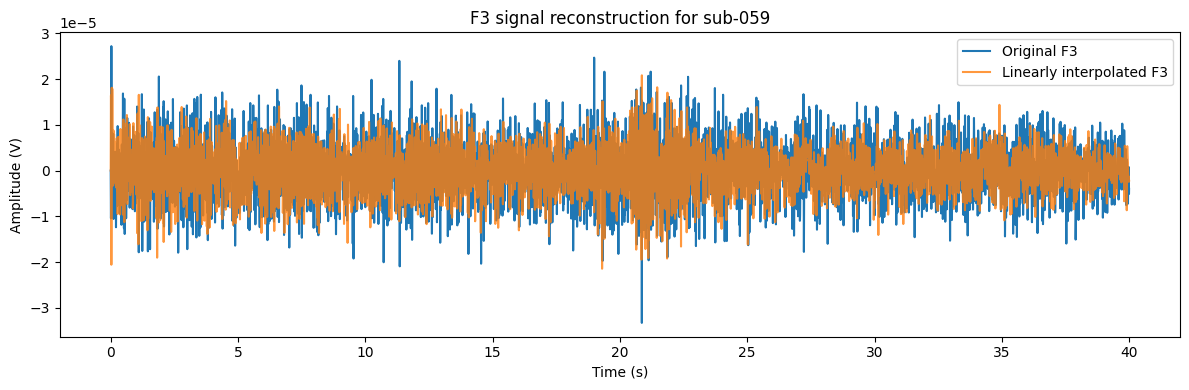

In [9]:
subject_to_plot = "sub-059"
preview_path = processed_dir / f"{subject_to_plot}_task-eyesclosed_eeg_cleaned_raw.fif"

if preview_path.exists():
    raw = mne.io.read_raw_fif(preview_path, preload=True, verbose=False)
    data = raw.get_data()
    ch_names = raw.ch_names
    fs = raw.info["sfreq"]

    available_neighbors = [ch for ch in neighbors if ch in ch_names]
    f3_original = data[ch_names.index(target_channel)]

    # Use the same coordinate-based interpolation as in the metrics calculation.
    f3_linear = linear_spatial_interpolation(
        data=data,
        ch_names=ch_names,
        coords=coords,
        target_channel=target_channel,
        available_neighbors=available_neighbors,
    )

    start_sec = 0
    end_sec = 40
    start = int(start_sec * fs)
    end = min(int(end_sec * fs), raw.n_times)
    time = np.arange(start, end) / fs

    plt.figure(figsize=(12, 4))
    plt.plot(time, f3_original[start:end], label="Original F3")
    plt.plot(time, f3_linear[start:end], label="Linearly interpolated F3", alpha=0.8)
    plt.title(f"F3 signal reconstruction for {subject_to_plot}")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude (V)")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f"Preview file not found: {preview_path}")